# **Глава 3. Классификаторы в Scikit-Learn.**

## **Работа с MNIST.**

*Загрузим датасет.*

In [1]:
from sklearn.datasets import fetch_openml

In [2]:
mnist = fetch_openml("mnist_784", version=1, cache=True, as_frame=False)
mnist

{'data': array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784)),
 'target': array(['5', '0', '4', ..., '4', '5', '6'], shape=(70000,), dtype=object),
 'frame': None,
 'categories': {'class': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']},
 'feature_names': ['pixel1',
  'pixel2',
  'pixel3',
  'pixel4',
  'pixel5',
  'pixel6',
  'pixel7',
  'pixel8',
  'pixel9',
  'pixel10',
  'pixel11',
  'pixel12',
  'pixel13',
  'pixel14',
  'pixel15',
  'pixel16',
  'pixel17',
  'pixel18',
  'pixel19',
  'pixel20',
  'pixel21',
  'pixel22',
  'pixel23',
  'pixel24',
  'pixel25',
  'pixel26',
  'pixel27',
  'pixel28',
  'pixel29',
  'pixel30',
  'pixel31',
  'pixel32',
  'pixel33',
  'pixel34',
  'pixel35',
  'pixel36',
  'pixel37',
  'pixel38',
  'pixel39',
  'pixel40',
  'pixel41',
  'pixel42',
  'pixel43',
  'pixel44',


In [3]:
X, y = mnist["data"], mnist["target"]

In [4]:
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784))

In [5]:
y

array(['5', '0', '4', ..., '4', '5', '6'], shape=(70000,), dtype=object)

*Визуализируем один объект с помощью **`matplotlib`**.*

In [6]:
import random

In [7]:
import matplotlib
import matplotlib.pyplot as plt

In [8]:
random_index = random.randint(0, len(X) - 1)
some_digit = X[random_index]
some_digit_image = some_digit.reshape(28, 28)

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

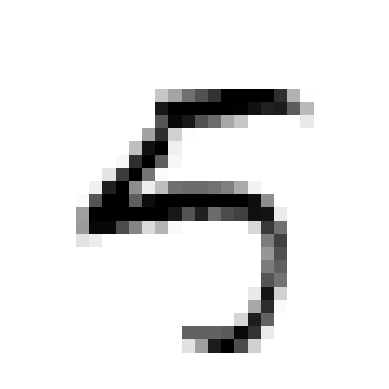

In [9]:
plt.imshow(some_digit_image, cmap=matplotlib.cm.binary, interpolation="nearest")
plt.axis("off")

In [10]:
y[random_index]

'5'

*Разделим данные на обучающую выборку и испытательный набор.*

In [11]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

*И перемешаем обучающую выборку.*

In [12]:
import numpy as np

In [13]:
shaffle_index = np.random.permutation(60000)
X_train, y_train = X_train[shaffle_index], y_train[shaffle_index]

## **Обучение двоичного классификатора.**

*Научим модель классифицировать тройки и "не тройки".*

In [14]:
y_train  # В датасете строки

array(['5', '9', '9', ..., '1', '4', '4'], shape=(60000,), dtype=object)

In [15]:
y_train_3 = (y_train == "3")
y_test_3 = (y_test == "3")

*Воспользуемся классификатором на основе метода стохастического градиентного спуска - `SGDClassifier`, который способен обрабатывать огромные наборы данных, по одному образцу за раз (подходит для динамического обучения).*

In [16]:
from sklearn.linear_model import SGDClassifier

In [17]:
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_3)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only i

In [18]:
sgd_clf.predict([some_digit])

array([False])

## **Показатели производительности.**

*Реализуем перекрёстную проверку для модели классификации самостоятельно.*

In [19]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

In [20]:
skfolds = StratifiedKFold(n_splits=3, random_state=42,shuffle=True)

*Непосредственно код-аналог `cross_val_score()`.*

In [21]:
for train_index, test_index in skfolds.split(X_train, y_train_3):
    clone_clf = clone(sgd_clf)
    X_train_folds = X_train[train_index]
    y_train_folds = y_train_3[train_index]
    X_test_folds = X_train[train_index]
    y_test_folds = y_train_3[train_index]

    clone_clf.fit(X_train_folds, y_train_folds)
    y_pred = clone_clf.predict(X_test_folds)
    n_correct = sum(y_pred == y_test_folds)
    print(n_correct / len(y_pred))

0.965825
0.9716
0.967575


*Далее перекрёсная проверка по K блокам, то есть разбиение обучающего набора на K блоков (в данном случае 3), выработку прогнозов и их оценку на каждом блоке с использованием модели, обученной на остальных блоках.*

In [22]:
from sklearn.model_selection import cross_val_score

In [23]:
cross_val_score(sgd_clf, X_train, y_train_3, cv=3, scoring="accuracy")

array([0.9104 , 0.95505, 0.97005])

*Точность ~95% - подозрительно много. Посмотрим на точность классификатора, который всегда выдаёт False.*

In [24]:
from sklearn.base import BaseEstimator

In [25]:
class Never3Classifier(BaseEstimator):
    def fit(self, X, y=None):
        pass
    def predict(self, X):
        return np.zeros(len(X), 1, dtype=bool)

In [26]:
never_3_clf = Never3Classifier()

In [27]:
cross_val_score(sgd_clf, X_train, y_train_3, cv=3, scoring="accuracy")

array([0.9104 , 0.95505, 0.97005])

*Оценка даже так очень высока. Проблема в том, что троек в датасете мало - ~10%, оттого и такая точность - ~90% случаев действительно не тройки. Такая проверка для классификаторов не подходит.*

*Посмотрим на **матрицу неточностей** - подсчёт количества неверных предсказаний для конкретного образца. Для этого нужно иметь предсказания.*

In [28]:
from sklearn.model_selection import cross_val_predict

In [29]:
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_3, cv=3)

*Вместо сумм очков оценки, как `cross_val_score()`, `cross_val_predict()` возвращает прогнозы, выработанные на каждом испытательном блоке.*

In [30]:
from sklearn.metrics import confusion_matrix

In [31]:
confusion_matrix(y_train_3, y_train_pred)

array([[51288,  2581],
       [  709,  5422]])

*Результаты трактуются так:*
- *51436 - слева сверху количество не троек, которые были верно классифицированны, как не тройки (истинно отрицательные классификации, true negative - TN),*
- *2433 - справа сверху - не тройки, которые были ошибочно предсказаны, как тройки (ложноположительные классификации, false positive - FP),*
- *769 - слева снизу - тройки, которые неверно классифицированны, как не тройки (ложноотрицательные классификации, false negative - FN),*
- *5362 - справа снизу - тройки, которые были верно выбраны, как тройки (истинно положительные классификации, true positive - TP).*

*Для идеального классификатора матрица выглядела бы вот так.*

In [32]:
y_train_perfect_predictions = y_train_3

In [33]:
confusion_matrix(y_train_3, y_train_perfect_predictions)

array([[53869,     0],
       [    0,  6131]])

## **Точность (`precision`) и полнота (`recall`).**

$$
\text{Точность} = \frac{TP}{TP + FP}
$$

$$
\text{Полнота} = \frac{TP}{TP + FN}
$$

In [34]:
from sklearn.metrics import precision_score, recall_score

In [35]:
precision_score(y_train_3, y_train_pred)

0.6774959390228664

In [36]:
recall_score(y_train_3, y_train_pred)

0.8843581797422932

***Среднее гармоническое** точности и полноты - мера F1.*

$$
F_1 = \frac{2}{\frac{1}{\text{точность}} + \frac{1}{\text{полнота}}} = 2 * \frac{\text{точность} * \text{полнота}}{\text{точность} + \text{полнота}} = \frac{TP}{TP + \frac{FN + FP}{2}}
$$

In [37]:
from sklearn.metrics import f1_score

In [38]:
f1_score(y_train_3, y_train_pred)

0.7672279609452385

*С увеличением точности уменьшается полнота и наоборот. На порог (по умолчанию он - 0), от которого зависит и точность, и полнота можно "повлиять" только так.*

In [39]:
y_scores = sgd_clf.decision_function([some_digit])  # Сумма очков для образца, показанного выше (8)
y_scores

array([-9366.37674562])

In [40]:
threshold = 0
some_digit_pred = (y_scores > threshold)  # Предсказание ложное, так как сумма очков меньше заданного порога
some_digit_pred

array([False])

In [41]:
threshold = -20000
some_digit_pred = (y_scores > threshold)  # Предсказание истинно, так как сумма очков больше заданного порога
some_digit_pred

array([ True])

## **Кривая точности - полноты.**

*Поймём какой порог лучше использовать.*

In [42]:
y_scores = cross_val_predict(sgd_clf, X_train, y_train_3, cv=3, method="decision_function")

In [43]:
from sklearn.metrics import precision_recall_curve

In [44]:
precisions, recalls, thresholds = precision_recall_curve(y_train_3, y_scores)

In [45]:
def plot_precision_recall_vs_threshold(precisions, recalls, thresholds):
    plt.plot(thresholds, precisions[:-1], "b--", label="Точность")
    plt.plot(thresholds, recalls[:-1], "g-", label="Полнота")
    plt.xlabel("Порог")
    plt.legend(loc="center left")
    plt.ylim([0, 1])
    # plt.xlim([-700000, 700000])

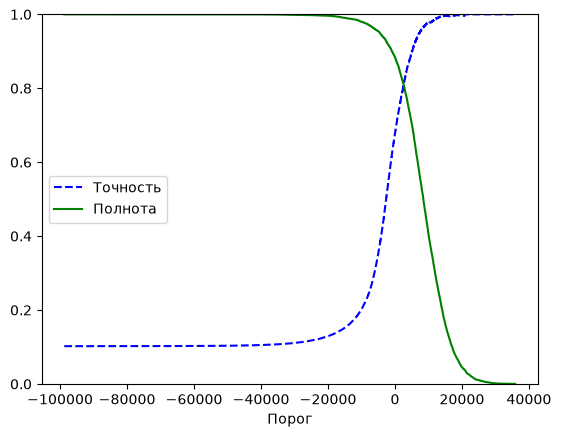

In [46]:
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)

In [47]:
def plot_precision_vs_recall(precisions, recalls):
    plt.plot(recalls, precisions)
    plt.xlabel("Полнота")
    plt.ylabel("Точность")
    plt.grid()

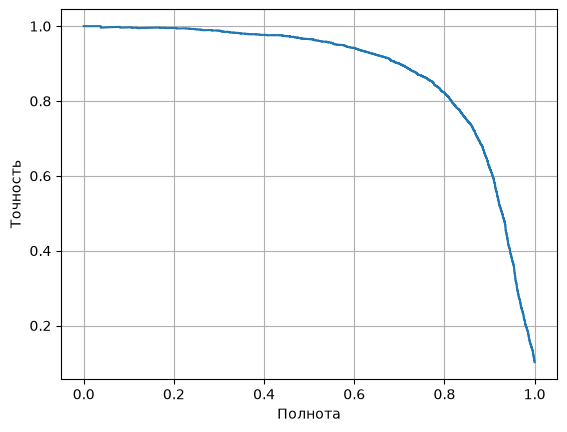

In [48]:
plot_precision_vs_recall(precisions, recalls)

In [49]:
y_train_pred_better = (y_scores > -1000)

In [50]:
precision_score(y_train_3, y_train_pred_better)

0.615256310463694

In [51]:
recall_score(y_train_3, y_train_pred_better)

0.9024628934920894

## **Кривая рабочей характеристики приёмника (Receiver Operating Characteristic - ROC).**

*Показывает полноту по отношению к доле ложноположительных классификаций (False Positive Rate - FPR) - пропорция отрицательных образцов, которые были некорректно классифицированы как положительные, равна единице минут доля истинно отрицательных классификаций (True Negative Rate - TNR) - пропорция отрицательных образцов, которые были корректно классифицированны как отрицательные.*

*Доля TNR называется специфичностью (`specificity`). То есть ROC показывает полноту в сравнении с $1 - \text{специфичность}$.*

In [52]:
from sklearn.metrics import roc_curve

In [53]:
fpr, tpr, thresholds = roc_curve(y_train_3, y_scores)

In [54]:
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], "k--")  # y = x - чисто случайный классификатор
    plt.axis([0, 1, 0, 1])
    plt.xlabel("False Positive Rate")
    plt.xlabel("True Positive Rate")

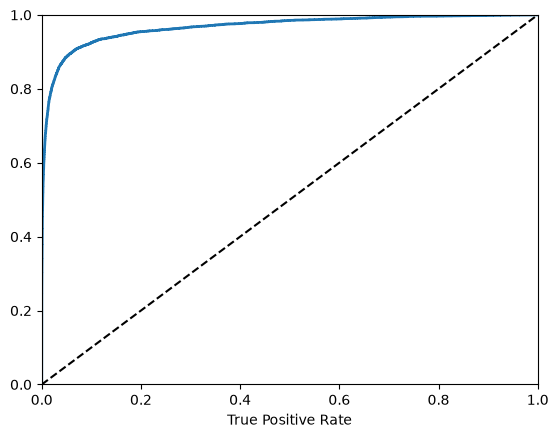

In [55]:
plot_roc_curve(fpr, tpr)

*Чем выше полнота (TPR), тем больше классификатор даёт ложноположительных классификаций (FPR). Хороший классификатор отдаляется от указанной линии настолько далеко, насколько это возможно.*

*Классификаторы можно сравнить площадью под кривой (Area Under the Curve - AUC), ROC AUC = 1 - безупречный, ROC AUC = 0.5 - случайный.*

In [56]:
from sklearn.metrics import roc_auc_score

In [57]:
roc_auc_score(y_train_3, y_scores)

0.9671777198591849

*Эмпирическое правило: когда положительный класс является редким или ложноположительные классификации заботят больше, чем ложноотрицательные, выбираем кривую PR, иначе - ROC.*

## **Обучим `RandomForestClassifier` и сравним кривую ROC и показатель ROC AUC с классификатором `SGDClassifier`.**

*`RandomForestClassifier` не имеет метода `decision_function()`, но есть `predict_proba()`, который возвращает массив, который содержит строку на образец и столбец на класс, содержащий вероятность того, что заданный образец принадлежит заданному классу.*

In [58]:
from sklearn.ensemble import RandomForestClassifier

In [59]:
forest_clf = RandomForestClassifier(random_state=42)

In [60]:
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_3, cv=3, method="predict_proba")

*Достанем **показатели**, так как нужны они, а не вероятности.*

In [61]:
y_scores_forest = y_probas_forest[:, 1]
fpr_forest, tpr_forest, thresholds_forest = roc_curve(y_train_3, y_scores_forest)

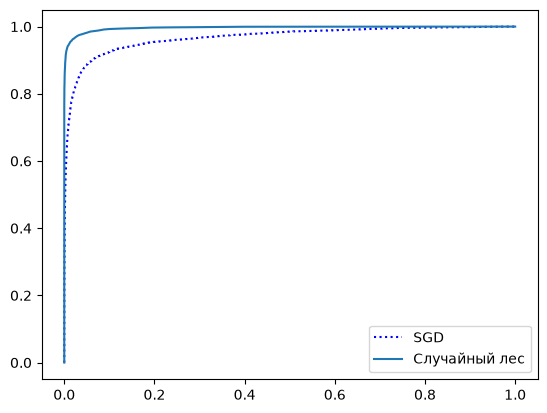

In [62]:
plt.plot(fpr, tpr, "b:", label = "SGD")
plt.plot(fpr_forest, tpr_forest, label = "Случайный лес")
plt.legend(loc="lower right")

*Случайный лес выглядит лучше.*

In [63]:
roc_auc_score(y_train_3, y_scores_forest)

0.9963861886698389

In [64]:
y_train_pred = cross_val_predict(forest_clf, X_train, y_train_3, cv=3)

In [65]:
precision_score(y_train_3, y_train_pred)

0.9935897435897436

In [66]:
recall_score(y_train_3, y_train_pred)

0.8342847822541184

*Все показатели отличные!*

## **Многоклассовая классификация.**